# Laporan UTS Machine Learning (Tugas Kelompok)

**Hands-on Machine Learning: Regresi, Klasifikasi, dan Clustering**

**Anggota kelompok:** Tarannia Raisha Putri (101032300231), Revalia Putri (101032330225)
**Repositori:** https://github.com/taraanrp/Midterm-Exam-Machine-Learning-Group-Task-

Semua angka dalam laporan ini dihasilkan oleh `kode/run_all.sh` (Python 3.12.3, seed 42; versi pustaka di `kode/requirements.txt`).

## Ringkasan

**Tugas 1 (regresi).** LightGBM kuantil pada log durasi, tanpa `jumlah_scan` dan `f30`. Pada validasi berbasis waktu (latih Jan-Jun, validasi Jul-Agu, tanpa 104 outlier ekstrem), pinball P50 = 7.08 jam (baseline grup 10.48, Ridge 7.66). Cakupan P90 sebelum kalibrasi 86.3%, setelah conformal per layanan 90.0%.

**Tugas 2 (klasifikasi).** LightGBM tanpa penanganan imbalance, dilatih hanya pada transaksi berlabel matang (sampai 10 Agu), tanpa `flag_review_manual` (bocor) dan `v15` (drift). PR-AUC validasi Jul-Agu = 0.669 (logistik 0.557). Pola fraud baru di QRIS (merchant muda, mulai 28 Jul) ditangani dengan bobot 5x pada transaksi sejak tanggal itu. Dengan aturan keputusan p x nominal > Rp 25.000, total biaya paruh akhir validasi Rp 54.8 jt berbanding Rp 204.4 jt (tidak menandai) dan Rp 749.9 jt (menandai semua).

**Tugas 3 (clustering).** 113,264 pelanggan aktif dikelompokkan dengan K-Means pada 36 fitur terpilih menjadi 4 segmen; 6,736 pelanggan tanpa pesanan menjadi satu segmen tersendiri, dan 1,828 pelanggan berperilaku ekstrem diberi label -1. Struktur datanya lemah (silhouette sekitar 0,08), sehingga hasil ini harus dibaca dengan hati-hati (lihat Bagian 4).

> **Catatan jujur tentang metrik.** Angka pinball mentah pada validasi (sekitar 11 jam) didominasi sekitar 100 paket dengan durasi ribuan jam. Kami melaporkan kedua versi (mentah dan tanpa outlier). Skor sebenarnya pada test tersembunyi tidak kami ketahui.

## 1. Tugas 1: Regresi, estimasi durasi pengiriman

### 1.a Audit data

| Temuan | Bukti | Tindakan |
| --- | --- | --- |
| `jumlah_scan` tidak tersedia saat pickup (bocor) | Terkumpul selama pengiriman. Korelasi Spearman dengan durasi 0.77. Rata-rata 9.65 di train vs 1.50 di test. | Dibuang dari semua model. |
| `f30` bergeser linear terhadap waktu | Rata-rata per bulan 0.055 (Jan) sampai 1.148 (Okt). Korelasi dengan durasi -0.004. | Dibuang. |
| Outlier target | 370 paket durasi > 1000 jam (maks 25452 jam; P99 = 225 jam). | Dibuang dari data latih saja. Validasi tetap dilaporkan dengan dan tanpa outlier. |
| `jarak_km` = 0 | 703 baris, tidak masuk akal. | Diubah menjadi NaN. |
| `berat_kg` kosong | 5.6% baris. | Dibiarkan NaN (LightGBM) + penanda kosong. |
| Kurir baru di test | K13: 3.9% baris test, tidak ada di train. | Kategori tak dikenal -> NaN, dengan masking 4% saat latih. |
| `antrean_hub_asal`, `f35`, `f17` sedikit bergeser | Rata-rata antrean 3329 (train) vs 4619 (test). | Dipertahankan (tren musiman wajar, tidak bocor). |

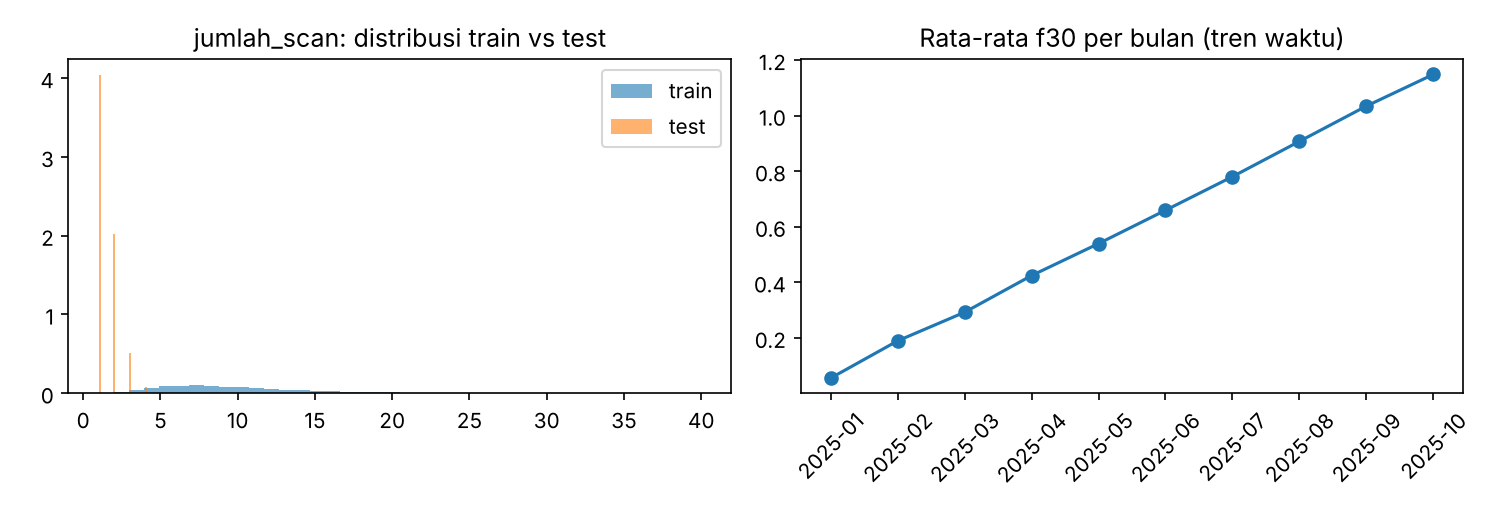

*Gambar 1. Distribusi `jumlah_scan` train vs test; rata-rata `f30` per bulan*

**Dampak kebocoran.** Pada validasi Jul-Agu (tanpa outlier) pinball P50 dengan `jumlah_scan` 5.61 jam vs 7.08 tanpanya, sehingga fitur ini tampak sangat membantu. Namun pada test distribusinya runtuh, dan median prediksi P50 turun menjadi 51.10 jam (tanpa fitur: 61.38; median train 61.70). Model dengan `f30` memberi pinball P50 7.11 (tanpa outlier), sedikit lebih buruk. Dampak outlier pada model log-target (Ridge) kecil: pinball P50 11.510 (dengan) vs 11.508 (tanpa); pengaruh outlier pada model kuantil tidak kami ukur terpisah.

### 1.b Skema validasi

Tes sebenarnya adalah dua bulan ke depan (Sep-Okt), jadi validasi dibuat berbasis waktu: **Fold A** (latih Jan-Apr, validasi Mei-Jun) hanya untuk tuning hiperparameter dan jumlah pohon; **Fold B** (latih Jan-Jun, validasi Jul-Agu) hanya untuk pelaporan dan kalibrasi, sehingga tidak ada tuning yang menyentuh data pelaporan. Sebagai pembanding, validasi acak 80/20:

| Skema | Pinball P50 | Pinball P90 | Cakupan P90 |
| --- | ---: | ---: | ---: |
| Waktu (Fold B, tanpa outlier) | 7.08 | 4.55 | 86.4% |
| Acak 80/20 (tanpa outlier) | 6.79 | 4.16 | 88.6% |

Validasi acak lebih optimistis (pinball P50 6.79 vs 7.08), dan cakupan P90 pada validasi waktu (86.4%) di bawah target, menandakan geseran antarwaktu yang tidak terlihat pada validasi acak.

### 1.c Model dan tuning

Tiga model: (1) baseline kuantil empiris per layanan x pulau tujuan; (2) Ridge pada log durasi + kuantil residual per layanan; (3) LightGBM kuantil pada log durasi (kuantil log = log kuantil, sehingga transformasi aman). Fitur kota memakai target encoding out-of-fold (smoothing 20). Tuning hanya pada Fold A, tiga konfigurasi:

| Konfigurasi | num_leaves | min_child | pinball P50 | pinball P90 | iterasi P50/P90 |
| ---: | ---: | ---: | ---: | ---: | ---: |
| 0 | 31 | 200 | 9.92 | 9.69 | 76/183 |
| 1 | 63 | 100 | 9.88 | 9.71 | 47/198 |
| 2 | 127 | 50 | 9.92 | 9.76 | 47/139 |

Dipilih konfigurasi dengan rata-rata pinball terkecil (`num_leaves=63`, `min_child_samples=100`, laju belajar 0,1). Hasil Fold B:

| Model | P50 (tanpa outlier) | P90 (tanpa outlier) | P50 (mentah) | P90 (mentah) | Cakupan P90 (mentah) |
| --- | ---: | ---: | ---: | ---: | ---: |
| Baseline grup | 10.48 | 6.45 | 14.32 | 13.32 | 88.8% |
| Ridge (log) | 7.66 | 4.69 | 11.51 | 11.58 | 89.5% |
| **LightGBM kuantil (log)** | **7.08** | **4.55** | **10.92** | **11.45** | **86.3%** |

### 1.d Kategori kardinalitas tinggi dan kategori baru

`kota_tujuan` (405 nilai) dan `kota_asal` memakai target encoding out-of-fold; kota baru jatuh ke rata-rata global (tidak ada kota tujuan baru di test). Kurir K13 hanya ada di test, jadi kami mensimulasikannya: kurir K12 dikeluarkan dari data latih Fold B lalu dievaluasi pada 2808 paket K12. Pinball P50 7.567 dengan masking 4% saat latih vs 7.657 tanpa masking. Selisihnya kecil, tetapi masking mengajarkan model jalur 'kurir tak dikenal', sehingga dipakai.

### 1.e Ketidakpastian: P50, P90, dan kalibrasi

P90 dari model memiliki cakupan di bawah 90% pada periode berikutnya. Kami mengkalibrasi dengan conformal prediction ala Mondrian pada skala log: offset aditif per layanan diambil dari kuantil skor nonkonformitas pada data kalibrasi. Uji out-of-time: kalibrasi pada Juli, uji pada Agustus.

| Agustus (uji) | Cakupan P90 | Pinball P90 |
| --- | ---: | ---: |
| Sebelum kalibrasi | 86.5% | 11.49 |
| Setelah conformal | 90.1% | 11.40 |

Offset final dari seluruh validasi Jul-Agu (skala log): ekspres +0.040, hemat +0.059, kargo +0.056, reguler +0.064. Dengan offset ini cakupan P90 pada validasi menjadi 90.0%. Kami memaksa p90 ≥ p50 pada keluaran.

### 1.f Analisis error, SHAP

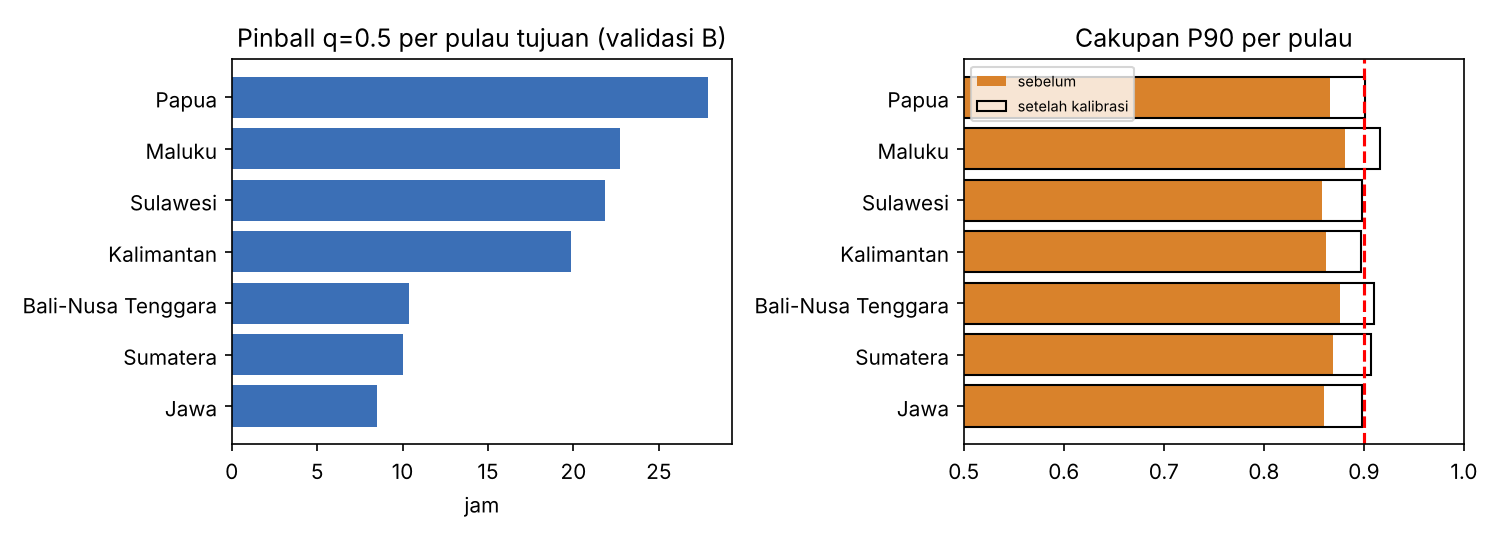

*Gambar 2. Pinball q=0.5 per pulau tujuan; cakupan P90 per pulau sebelum dan sesudah kalibrasi (validasi B)*

| Layanan | n | pinball P50 | pinball P90 | cakupan P90 | cakupan setelah kalibrasi |
| --- | ---: | ---: | ---: | ---: | ---: |
| ekspres | 10106 | 5.55 | 5.10 | 88.2% | 90.0% |
| hemat | 22760 | 14.17 | 14.61 | 86.1% | 90.0% |
| kargo | 6867 | 10.99 | 10.03 | 85.8% | 90.0% |
| reguler | 28871 | 10.22 | 11.52 | 85.9% | 90.0% |

Error terbesar ada pada layanan hemat (pinball P50 14.17) dan paling kecil pada ekspres (5.55); pulau tujuan dengan error terbesar adalah Papua (27.89). Kurir K07 paling sulit (17.60), K11 paling mudah (6.98). Setelah kalibrasi cakupan P90 tiap layanan berada di sekitar 90%, tetapi cakupan per pulau belum dijamin karena kalibrasi hanya per layanan.

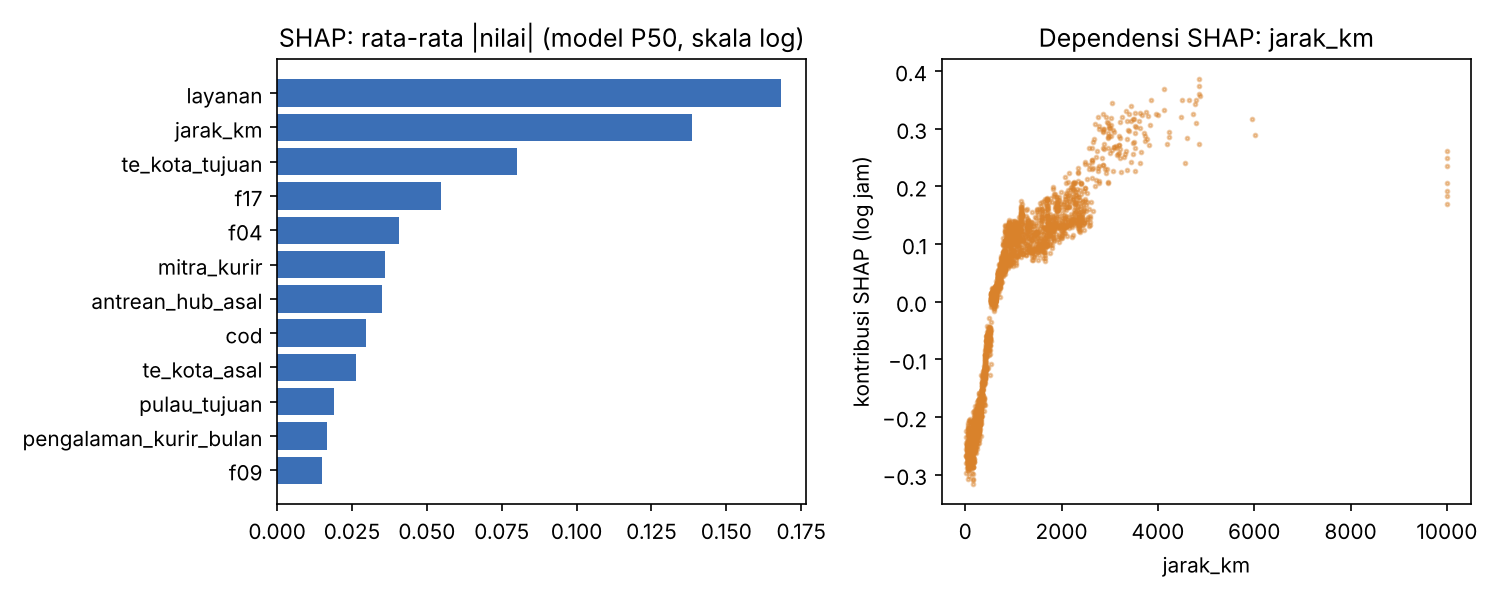

*Gambar 3. SHAP rata-rata |nilai| (model P50, skala log); dependensi SHAP `jarak_km`*

**SHAP** (model P50, skala log, 3.000 sampel validasi). Fitur terpenting: `layanan` (0.168), `jarak_km` (0.138), `te_kota_tujuan` (0.080), `f17` (0.055), `f04` (0.041), `mitra_kurir` (0.036). Jenis layanan dan jarak mendominasi, diikuti efek kota tujuan (target encoding) dan beberapa fitur anonim (`f17`, `f04`). Kontribusi jarak naik tajam sampai sekitar 2.000 km lalu melandai (panel kanan); beberapa titik di sekitar 10.000 km sedikit lebih rendah, jumlahnya sedikit sehingga tidak kami tafsirkan. Fitur anonim hanya dapat ditafsirkan sebagai 'penting', bukan secara substantif.

**Prediksi test:** median P50 62.65 jam dan median P90 86.79 jam (median durasi train 61.70 jam), konsisten dengan distribusi latih.

## 2. Tugas 2: Klasifikasi, deteksi fraud

### 2.a Audit label dan fitur

| Temuan | Bukti | Tindakan |
| --- | --- | --- |
| Label belum matang di ujung data latih | Fraud rate matang (1 Jul-10 Agu) 0.7%, tetapi minggu terakhir (25-31 Agu) hanya 0.1%. Fraud dikonfirmasi belakangan, sehingga transaksi baru tampak 'bersih' padahal belum terkonfirmasi. | Latih hanya pada transaksi sampai 10 Agu. Validasi dilakukan dengan jeda 21 hari. |
| `flag_review_manual` bocor | AUC sendirian 0.89; fraud rate 30.4% bila 1 vs 0.1% bila 0. 80% fraud punya flag. Ini keputusan tinjauan setelah transaksi, bukan fakta saat transaksi terjadi. Porsi flag berbeda: 1.7% (train) vs 1.2% (test). | Dibuang. |
| `v15` bergeser linear | Rata-rata per bulan 0.14 (Jan) sampai 2.88 (Okt), AUC terhadap label 0.49 (tanpa sinyal). | Dibuang. |
| `menit_sejak_trx_terakhir` mengikuti panjang riwayat | Median naik dari 8073 (Jan) ke 39278 (Okt) karena riwayat data dimulai 1 Jan. | Dipotong pada 7 hari, lalu log. |
| `hari_libur` berbeda | 5.7% (train) vs 1.6% (test), tanpa sinyal. | Dibuang. |

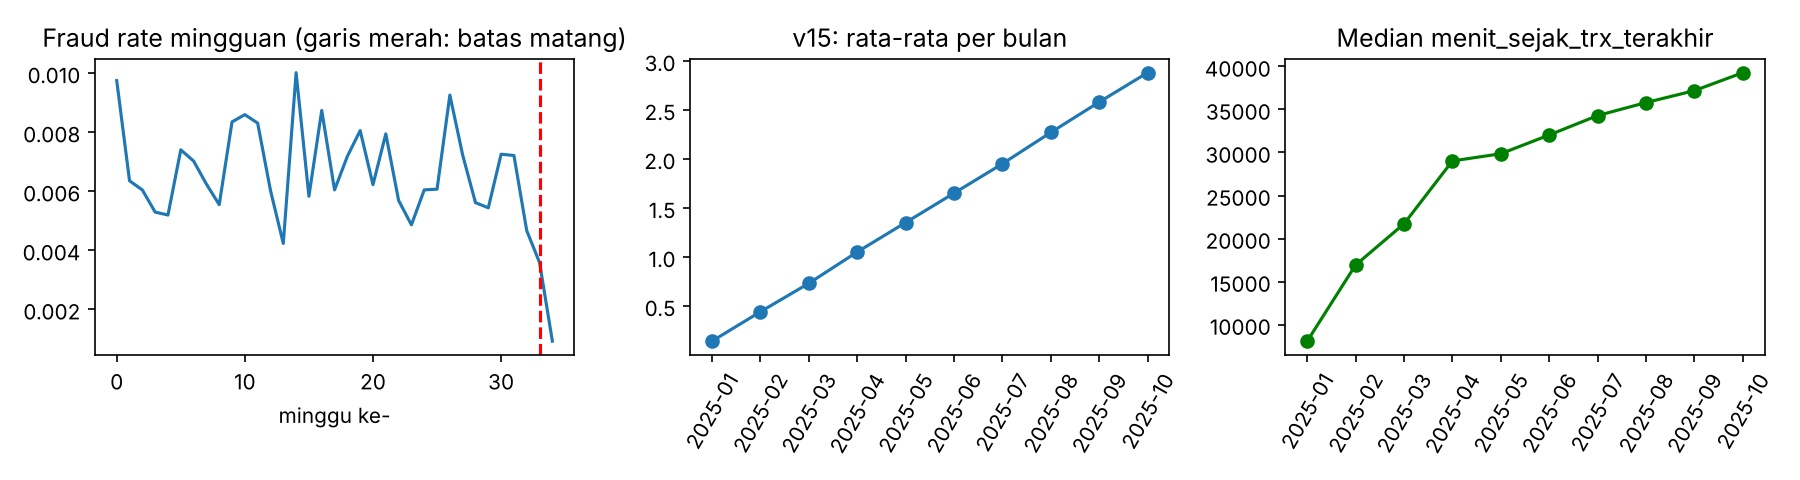

*Gambar 4. Fraud rate mingguan (garis merah: batas matang); rata-rata `v15` per bulan; median `menit_sejak_trx_terakhir` per bulan*

Pengguna test yang juga ada di train: 85%. Fitur riwayat tambahan dibuat hanya dari masa lalu: hitungan transaksi pengguna/merchant/pasangan dalam 30 hari terakhir, rasio nominal terhadap rata-rata 30 hari, hitungan merchant 1 dan 24 jam, hitungan pengguna 10 menit. Jendela dipakai (bukan hitungan kumulatif) agar fitur stasioner. Pada percobaan awal dengan hitungan kumulatif, AUC adversarial sedikit lebih tinggi (0,87 vs 0,84), sehingga diganti jendela. Tidak ada fitur berbasis label (label terlambat).

### 2.b Validasi berbasis waktu dengan jeda

Skema: **Fold A** (tuning): latih 1 Jan-30 Apr, jeda 21 hari, validasi 22 Mei-30 Jun. **Fold B** (pelaporan): latih 1 Jan-15 Jun, jeda 21 hari, validasi 7 Jul-10 Agu (label matang). Jeda 21 hari meniru kenyataan bahwa saat model dilatih, label transaksi 21 hari terakhir belum lengkap. Model final dilatih sampai 10 Agu, lalu dipakai untuk 1 Sep dan seterusnya (jeda yang sama). Fold B: 272,927 latih (1873 fraud), 59,994 validasi (394 fraud).

### 2.c Ketidakseimbangan kelas: perbandingan pendekatan

| Pendekatan (Fold B) | PR-AUC | ROC-AUC |
| --- | ---: | ---: |
| Regresi logistik (baseline) | 0.557 | 0.959 |
| **LightGBM tanpa penanganan** | **0.669** | **0.981** |
| LightGBM class weight (scale_pos_weight=12.0) | 0.622 | 0.979 |
| LightGBM undersampling negatif 10% + koreksi probabilitas | 0.649 | 0.981 |
| LightGBM + bobot recency (paruh-hidup 45 hari) | 0.664 | 0.983 |

Tuning Fold A (PR-AUC): `num_leaves` 15 -> 0.772, `num_leaves` 63 -> 0.769; dipilih `num_leaves` 15. Class weight dan undersampling tidak mengalahkan model biasa pada PR-AUC (metrik yang dipakai di penilaian). Tuning threshold dilakukan di tahap keputusan biaya (2.e), bukan pada skor.

### 2.d Pattern shift: lonjakan fraud QRIS di merchant muda

| Minggu validasi (Fold B) | n | fraud | PR-AUC |
| --- | ---: | ---: | ---: |
| 2025-07-07/2025-07-13 | 12603 | 91 | 0.764 |
| 2025-07-14/2025-07-20 | 11588 | 65 | 0.778 |
| 2025-07-21/2025-07-27 | 11590 | 63 | 0.739 |
| 2025-07-28/2025-08-03 | 11585 | 84 | 0.734 |
| 2025-08-04/2025-08-10 | 12628 | 91 | 0.467 |

PR-AUC stabil sekitar 0,73-0,78 sampai akhir Juli, lalu turun ke 0.467 pada 4-10 Agu. Pemeriksaan komposisi fraud menunjukkan penyebabnya: porsi QRIS dalam seluruh fraud sekitar 3-5% per bulan (Jan-Jul) melonjak menjadi 34% pada Agustus, padahal porsi QRIS dalam seluruh transaksi stabil sekitar 22%. Jadi ini pola fraud baru, bukan kenaikan volume QRIS.

| Minggu (QRIS) | n transaksi | fraud |
| --- | ---: | ---: |
| 2025-07-07/2025-07-13 | 2711 | 3 |
| 2025-07-14/2025-07-20 | 2543 | 3 |
| 2025-07-21/2025-07-27 | 2501 | 1 |
| 2025-07-28/2025-08-03 | 2548 | 13 |
| 2025-08-04/2025-08-10 | 2763 | 34 |

Pola baru (28 Jul-10 Agu): 47 fraud QRIS di 36 merchant, dengan umur merchant median 18 hari (fraud QRIS sebelumnya: 865 hari), nominal median Rp 1,500,000 (sebelumnya Rp 464,400), kategori jasa_lainnya 43%, toko_online 28% (sebelumnya didominasi fashion, kecantikan, elektronik). Fraud rate pada merchant berumur ≤ 30 hari naik dari 4.4% menjadi 10.3%. Median fitur risiko pengguna pada fraud baru ini (perangkat baru, login gagal, transaksi 1 jam) bernilai nol, sehingga model yang dilatih sebelum pola ini tidak punya sinyal kuat untuk menangkapnya; ini konsisten dengan kelemahan kanal QRIS di 2.f. Merchant-merchant ini juga muncul di test (311 transaksi).

| Adaptasi (latih sampai 4 Agu, uji 5-10 Agu) | PR-AUC semua | PR-AUC QRIS | biaya aturan (Rp) |
| --- | ---: | ---: | ---: |
| Tanpa bobot | 0.577 | 0.459 | 12,082,300 |
| **Bobot 5x untuk transaksi sejak 28 Jul** | **0.663** | **0.660** | **11,243,500** |
| Recency, paruh-hidup 14 hari | 0.656 | 0.662 | 10,511,600 |
| Recency, paruh-hidup 45 hari | 0.617 | 0.573 | 11,949,600 |

Hanya 76 fraud (25 QRIS) pada jendela uji ini, sehingga kesimpulannya tentatif dan pemilihan varian pada jendela yang sama bersifat optimistis. Pembobotan 5x sejak 28 Jul menaikkan PR-AUC dari 0.577 menjadi 0.663 (QRIS: 0.459 menjadi 0.660); recency 14 hari serupa. Dipilih bobot 5x untuk model final. Bobot recency 45 hari di Fold B tidak membantu (PR-AUC 0.664 vs 0.669) karena Fold B dilatih sampai 15 Juni dan belum melihat pola baru. Pada test, model final memberi probabilitas rata-rata 0.123 untuk 311 transaksi di merchant tersebut dan menandai 109 di antaranya; kami tidak bisa memverifikasinya tanpa label test.

Validasi adversarial (test vs Jul-Agu, hanya kovariat) memberi AUC 0.84; fitur pembeda utama: `umur_merchant_hari`, `m_cnt_30h`, `m_cnt_24j`. `umur_merchant_hari` bertambah seiring waktu secara alami, jadi sebagian geseran ini wajar tetapi tidak sepenuhnya kami hilangkan.

### 2.e Kalibrasi dan keputusan berbasis biaya

| Paruh akhir validasi B | Brier | ECE | rata-rata prob |
| --- | ---: | ---: | ---: |
| Mentah | 0.00371 | 0.00101 | 0.0067 |
| Platt | 0.00372 | 0.00145 | 0.0072 |
| Isotonik | 0.00369 | 0.00162 | 0.0071 |
| Laju fraud aktual | | | 0.0069 |

Kalibrasi dipasang pada paruh awal validasi B dan diuji pada paruh akhir (urutan waktu). Selisih ketiganya kecil karena LightGBM sudah cukup terkalibrasi; kami memakai Platt (dua parameter, monoton sehingga PR-AUC tidak berubah, dan lebih stabil daripada isotonik).

| Kebijakan (paruh akhir validasi B) | Total biaya |
| --- | ---: |
| tidak_tandai_apa_pun | Rp 204,401,500 |
| tandai_semua | Rp 749,925,000 |
| **aturan_biaya_platt (p*nominal>25rb)** | **Rp 54,802,500** |
| aturan_biaya_isotonik | Rp 52,578,800 |
| aturan_biaya_mentah (tanpa kalibrasi) | Rp 53,977,500 |
| threshold_global_p (dituning paruh awal) | Rp 61,651,200 |

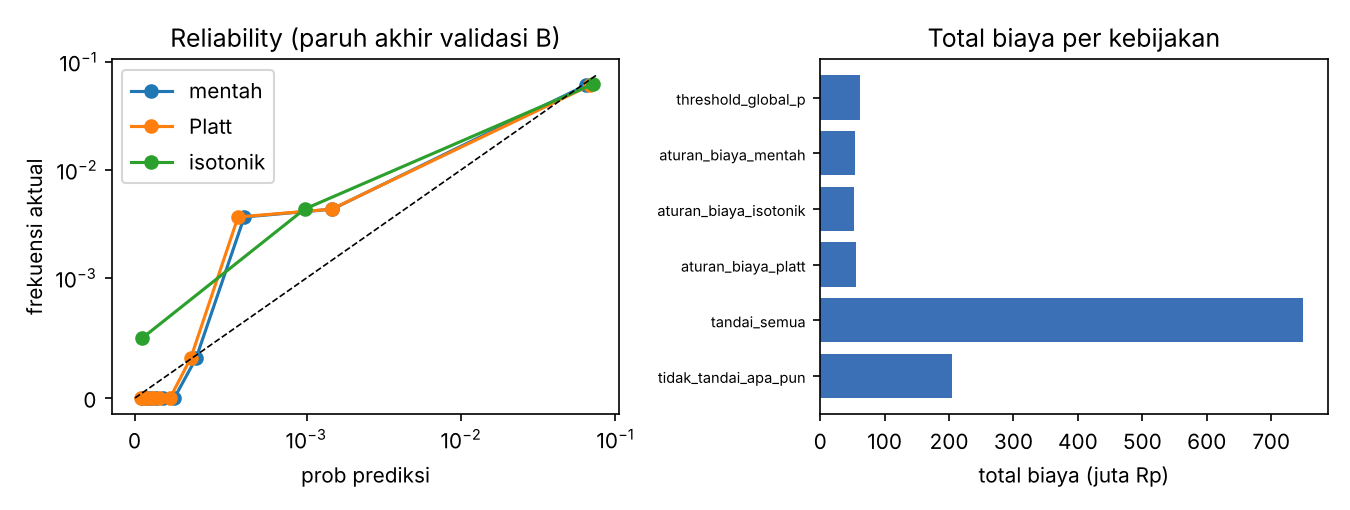

*Gambar 5. Reliability diagram (paruh akhir validasi B); total biaya per kebijakan*

Biaya = nominal fraud yang lolos + Rp 25.000 x jumlah transaksi ditandai. Aturan optimal untuk probabilitas terkalibrasi: tandai bila p x nominal > 25.000 (kerugian yang diharapkan terhindar melebihi biaya tinjauan). Pada 29,997 transaksi (207 fraud, nominal fraud Rp 204.4 jt) aturan ini menandai 435 transaksi dan menangkap 72.0% fraud, dengan biaya Rp 54.8 jt. Itu sekitar 27% dari biaya tidak menandai apa pun dan 7% dari biaya menandai semuanya. Threshold global pada p (dituning di paruh awal) lebih mahal (Rp 61.7 jt) karena mengabaikan nominal. Selisih aturan Platt, isotonik, dan tanpa kalibrasi kecil dan dalam rentang noise (hanya 207 fraud di paruh akhir).

### 2.f Analisis error

| Kanal | n | fraud | PR-AUC | recall (aturan biaya) | biaya fraud lolos |
| --- | ---: | ---: | ---: | ---: | ---: |
| aplikasi | 26886 | 82 | 0.657 | 63.4% | Rp 5.1 jt |
| kartu | 7479 | 107 | 0.748 | 72.9% | Rp 4.9 jt |
| qris | 13066 | 54 | 0.188 | 37.0% | Rp 42.3 jt |
| va | 8928 | 89 | 0.739 | 87.6% | Rp 2.4 jt |
| web | 3635 | 62 | 0.846 | 77.4% | Rp 1.7 jt |

Dari 394 fraud di seluruh validasi B, 276 tertangkap dan 118 lolos. Kanal QRIS paling bermasalah: PR-AUC 0.188, recall 37.0%, dan Rp 42.3 jt dari kerugian lolos berasal dari QRIS. Kanal web, VA, dan kartu jauh lebih baik. Kelemahan QRIS konsisten dengan pola baru pada 2.d (model Fold B dilatih sebelum pola itu muncul); ini hipotesis yang sesuai dengan datanya, bukan hasil uji terpisah. Fraud yang lolos berpola 'tenang': median nominal 156,500 vs 664,700 untuk yang tertangkap; rata-rata `nominal_24j` 19,916 vs 343,099, `gagal_login_24j` 0.23 vs 1.03, `ganti_password_7h` 0.04 vs 0.30. Artinya model baik pada fraud yang disertai tanda ambil-alih akun (login gagal, ganti kata sandi, aktivitas padat), dan lemah pada fraud tunggal tanpa riwayat mencurigakan. Sebanyak 5.8% fraud bernominal di bawah Rp 25.000, yang secara ekonomi tidak layak ditinjau.

Fitur terpenting (gain, model LightGBM biasa): `trx_1j` (10.1%), `m_cnt_30h` (7.5%), `kategori_merchant` (7.0%), `perangkat_baru` (6.9%), `refund_merchant_30h` (6.2%), `menit_sejak_trx_terakhir` (5.6%).

**Prediksi test:** rata-rata prob terkalibrasi 0.0079; 1,729 transaksi (1.6%) ditandai.

## 3. Tugas 3: Clustering, segmentasi pelanggan

### 3.a Preprocessing

Temuan data: `rata2_keranjang` kosong pada 5.6% baris, tepat sama dengan pelanggan dengan `frekuensi_90h` = 0 (kosong berarti tidak ada pesanan). Ada 0.58% `rasio_konversi` > 1 (dipotong pada 1). `recency_hari` maksimum 1676 vs P99 217. Kamus data menyebut atribut CRM n01-n10, tetapi file berisi 15 kolom (n01-n15).

Perlakuan: log1p untuk variabel miring (belanja, frekuensi, recency, sesi, dll.); transformasi CLR (centered log-ratio, dengan penambahan 0,005 untuk nol) untuk porsi kategori dan porsi jam karena jumlahnya selalu 1; logit untuk persentase promo; penskalaan z lalu pemotongan pada +/-5 simpangan baku agar outlier tidak mendominasi jarak. `kota_tier` diperlakukan ordinal dan `perangkat` one-hot.

**Pelanggan tanpa pesanan.** 6,736 pelanggan (5.6%) tidak punya belanja 90 hari. Semua metrik belanja mereka nol, jadi jika ikut diklaster mereka akan membentuk kelompok sendiri yang mendominasi jarak. Mereka ditetapkan sebagai satu segmen tersendiri (label 4), dan klaster dibentuk pada 113,264 pelanggan aktif.

### 3.b Seleksi fitur dengan bukti

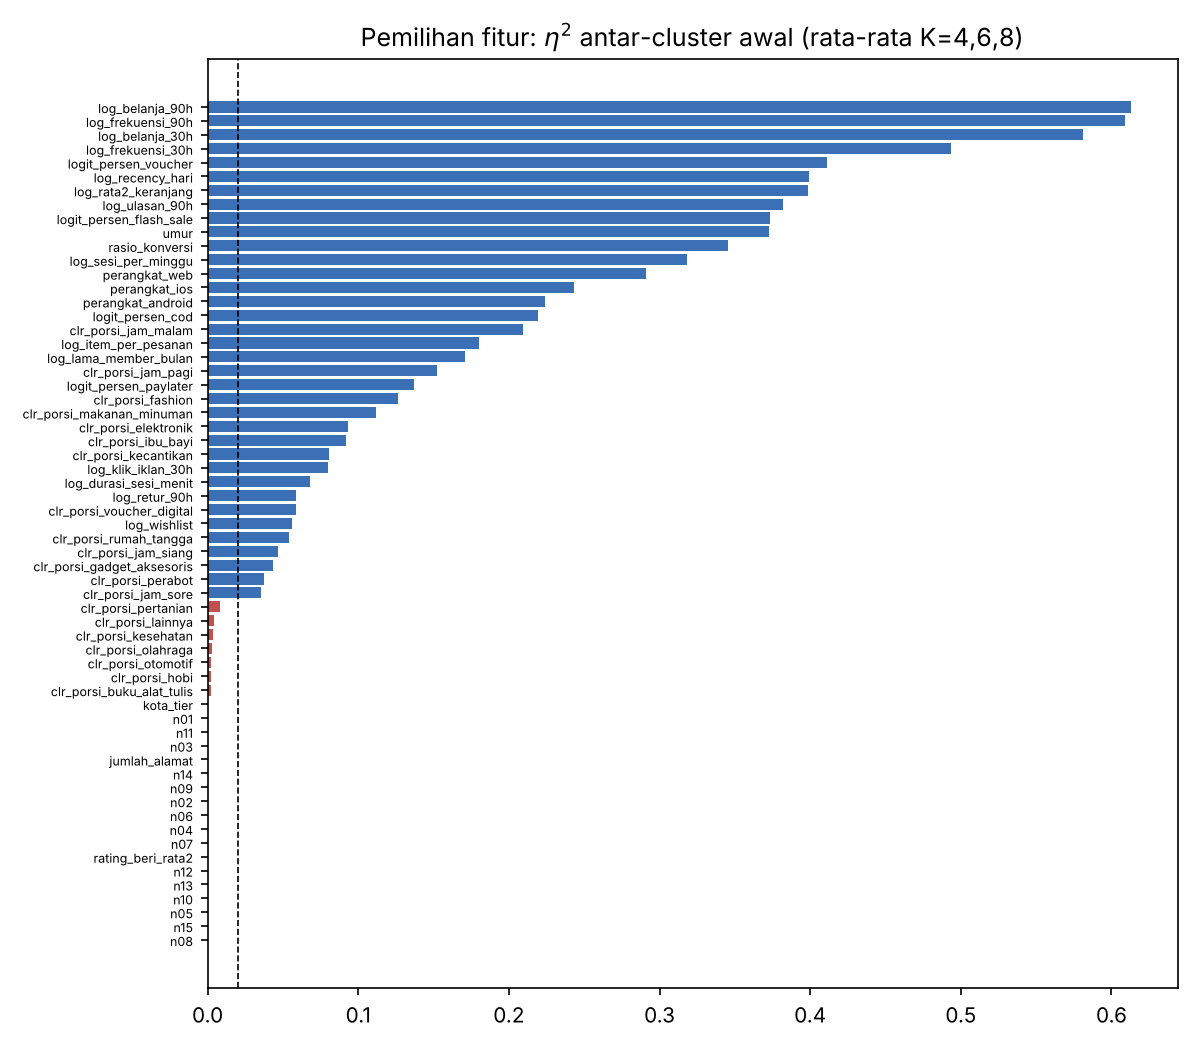

*Gambar 6. Pemilihan fitur — η² antar-cluster awal (rata-rata K=4,6,8), garis putus-putus = ambang 0,02*

Bukti: pada K-Means awal (K=4,6,8) dihitung eta kuadrat tiap fitur (porsi varians antar-cluster). Ambang 0,02. Seluruh 15 kolom n berada di bawah ambang, dan korelasi Spearman maksimum tiap kolom n dengan fitur non-n hanya 0.009-0.018, yaitu praktis tidak berhubungan dengan perilaku pelanggan. Mereka dibuang. Dibuang juga: `clr_porsi_olahraga`, `clr_porsi_hobi`, `clr_porsi_otomotif`, `clr_porsi_kesehatan`, `clr_porsi_buku_alat_tulis`, `clr_porsi_pertanian`, `clr_porsi_lainnya`, `rating_beri_rata2`, `kota_tier`, `jumlah_alamat`. Fitur dipakai: 36. Fitur yang paling membedakan: log belanja/frekuensi (90 dan 30 hari), persentase voucher, recency, rata-rata keranjang, ulasan, umur, dan rasio konversi. Keterbatasan: ambang 0,02 bersifat pilihan kami; fitur dengan eta kuadrat rendah bisa saja informatif untuk pembagian yang tidak dipilih K-Means.

### 3.c Metode dan jumlah cluster

| K | silhouette | Calinski-Harabasz | Davies-Bouldin | BIC (GMM) | gap | stabilitas ARI |
| ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 2 | 0.104 | 13669 | 2.78 | 4930443 | 1.526 | - |
| 3 | 0.082 | 10357 | 2.96 | 4172824 | 1.516 | 0.89 |
| **4** | **0.079** | **8733** | **2.99** | **4161517** | **1.523** | **0.80** |
| 5 | 0.068 | 7405 | 3.32 | 4111904 | 1.535 | 0.64 |
| 6 | 0.080 | 6604 | 2.86 | 4057940 | 1.549 | 0.64 |
| 7 | 0.066 | 6105 | 3.08 | 4061587 | 1.564 | 0.70 |
| 8 | 0.068 | 5627 | 2.94 | 4039018 | 1.590 | 0.72 |
| 9 | 0.068 | 5471 | 2.81 | 4025063 | 1.617 | 0.72 |
| 10 | 0.066 | 5130 | 2.78 | 4041443 | 1.627 | 0.68 |
| 11 | 0.063 | 4780 | 2.82 | 4033633 | 1.635 | - |
| 12 | 0.064 | 4504 | 2.89 | 4029200 | 1.629 | - |

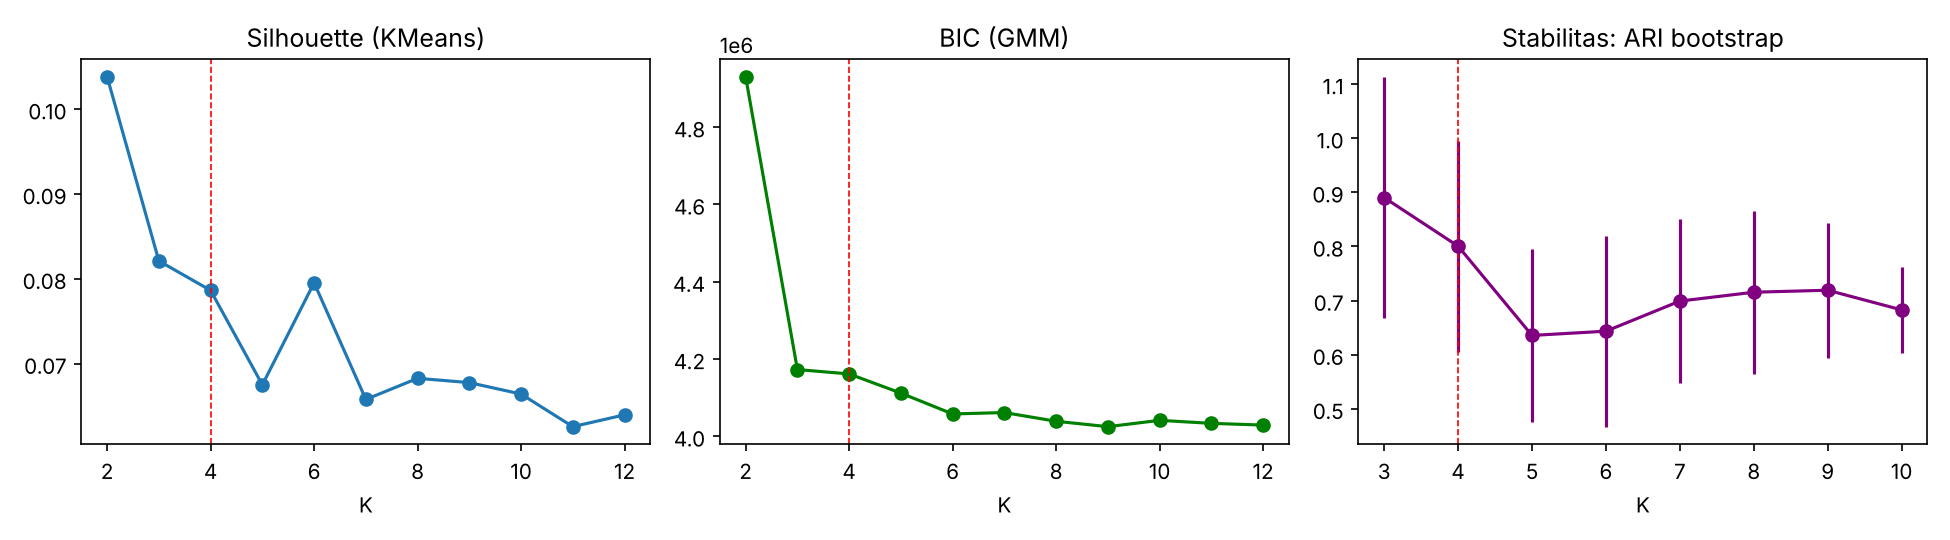

*Gambar 7. Silhouette (K-Means), BIC (GMM), dan stabilitas ARI bootstrap terhadap K; garis merah = K=4*

Kriteria tidak sepakat. Silhouette tertinggi di K=2 (0,104) tetapi pembagian dua kelompok kurang bermakna untuk pemasaran, dan silhouette di K=3-12 hanya 0,06-0,08. BIC terus turun hingga sekitar K=9 dan statistik gap naik hingga K=11 tanpa puncak jelas, yang menandakan tidak ada struktur diskret yang tegas. Stabilitas bootstrap (ARI antar dua subsampel 70%) turun dari 0,89 (K=3) menjadi 0,80 (K=4) dan 0,64 (K=5). Kami memilih K=4, K terbesar yang masih stabil (ARI ≥ 0,8), dengan silhouette yang setara dengan K=6. Ini kompromi, bukan optimum tegas; kombinasi dua kriteria (stabilitas dan silhouette) mendukungnya, sedangkan BIC dan gap menyarankan K lebih besar.

| Metode (K=4) | silhouette | Davies-Bouldin | Calinski-Harabasz | ukuran cluster |
| --- | ---: | ---: | ---: | --- |
| **K-Means** | **0.079** | **2.99** | **8733** | [16644, 27333, 42281, 27006] |
| Gaussian Mixture (PCA 15 dim) | 0.054 | 2.99 | 5175 | [73198, 12783, 17345, 9938] |
| Ward aglomeratif (subsampel 12k + kNN) | 0.080 | 2.72 | 7483 | [42275, 45128, 16070, 9791] |

ARI antar metode rendah: K-Means vs GMM 0.13, K-Means vs Ward 0.48, GMM vs Ward 0.20. GMM membentuk satu cluster sangat besar (73.198, hampir sama dengan jumlah pengguna Android, yang kemungkinan dipicu fitur biner perangkat), sehingga kurang bermakna. Stabilitas bootstrap pada K=4: K-Means 0.83 (sd 0.20), GMM 0.80 (sd 0.28). Karena silhouette dan stabilitas K-Means paling baik dan hasilnya paling mudah ditafsirkan, metode final adalah K-Means. Simpangan baku stabilitas besar (0,15-0,2), jadi perbedaan antar-K kecil tidak boleh dibaca terlalu jauh.

### 3.d Anomali (label -1)

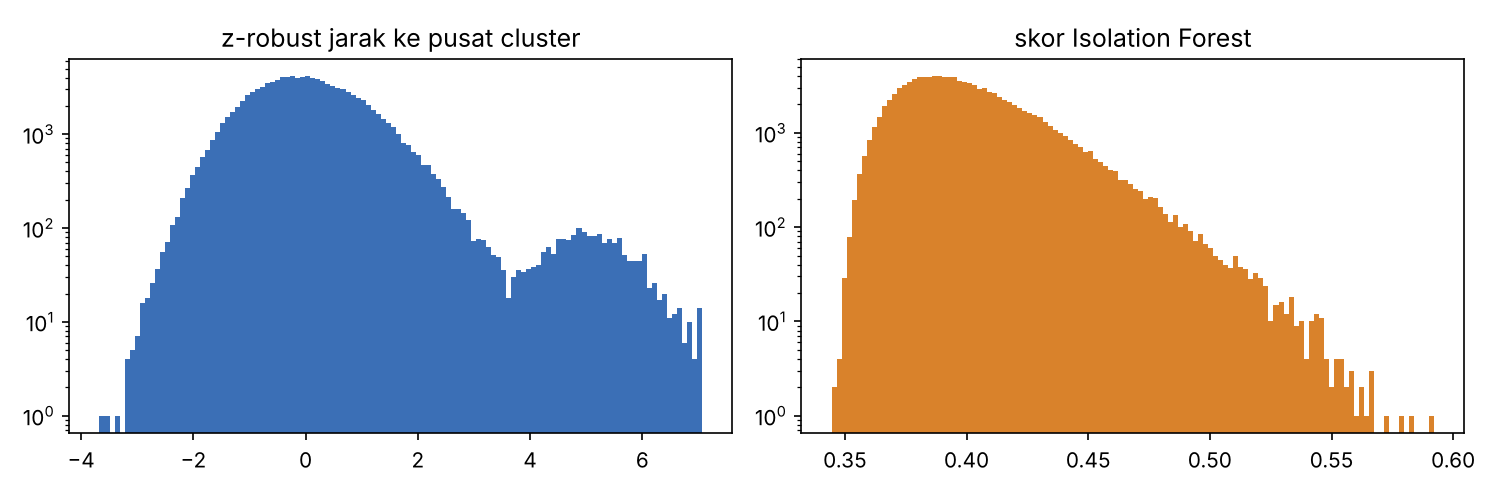

*Gambar 8. Histogram z-robust jarak ke pusat cluster; histogram skor Isolation Forest*

Histogram jarak-robust ke pusat cluster memperlihatkan dua mode: populasi normal dan 'bukit' kedua jauh dari pusat. Ambang diambil di lembah antar keduanya (z = 3.65), bukan persentase tetap, sehingga menandai 1,828 pelanggan (1.61%). 82% di antaranya juga berada di 5% skor teratas Isolation Forest. Profil anomali berbeda tajam: sesi per minggu rata-rata sekitar 226 (segmen lain 4-8), klik iklan 30 hari sekitar 186 (segmen lain sekitar 6), wishlist sekitar 140 (segmen lain sekitar 11), dengan rasio konversi median hanya 0.005. Pola ini mirip bot atau akun penjelajah ekstrem yang jarang membeli.

### 3.e Profil dan aksi pemasaran per segmen

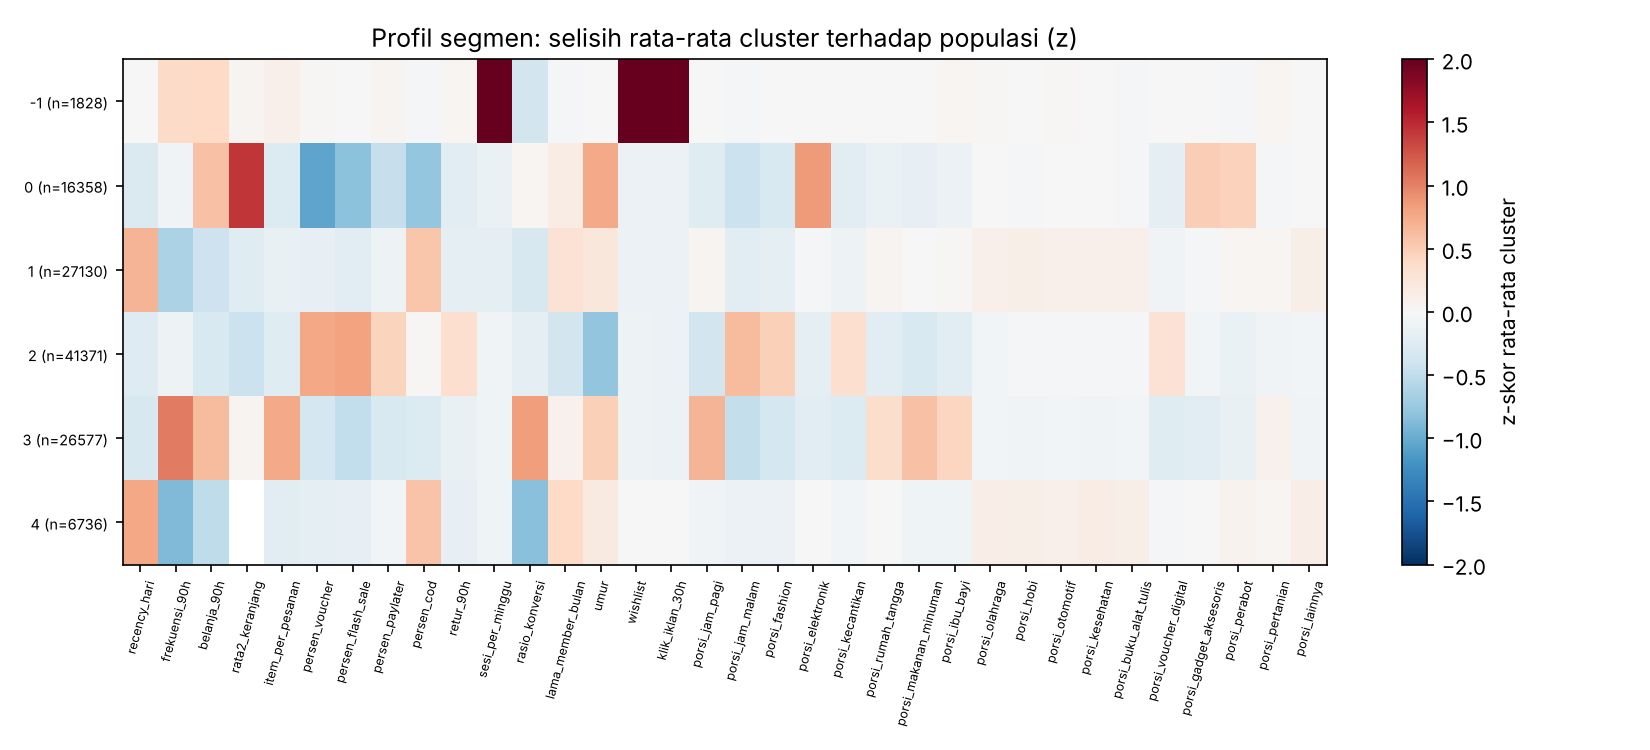

*Gambar 9. Profil segmen — selisih rata-rata cluster terhadap populasi (z)*

| Label | Nama segmen | n (%) | Ciri utama | Satu aksi pemasaran |
| ---: | --- | --- | --- | --- |
| 0 | Pembeli Bernilai Tinggi (Elektronik dan Gadget) | 16,358 (13.6%) | Keranjang rata-rata Rp 710 ribu (tertinggi), belanja 90 hari Rp 6,3 juta, porsi elektronik dan gadget tinggi, pengguna voucher rendah (21%), usia rata-rata 39 tahun. | Program bundling aksesoris, garansi dan tukar tambah, serta cicilan paylater untuk barang mahal. |
| 1 | Pelanggan Mulai Pasif | 27,130 (22.6%) | Recency 58 hari, hanya 2,8 pesanan dan belanja Rp 538 ribu dalam 90 hari, COD tinggi (43%). | Kampanye win-back: voucher personal berbatas waktu dan pengingat produk dari wishlist. |
| 2 | Pemburu Promo Muda | 41,371 (34.5%) | Usia 26 tahun, voucher 73% dan flash sale 62% dari pesanan, belanja malam (40%), fashion dan kecantikan dominan, retur tertinggi (1,31), anggota baru (14 bulan), keranjang kecil. | Notifikasi flash sale malam hari, panduan ukuran untuk menekan retur, dan insentif naik kelas keranjang (min. belanja). |
| 3 | Pembelanja Rutin Rumah Tangga | 26,577 (22.1%) | 21 pesanan per 90 hari, 5 barang per pesanan, belanja pagi (38%), makanan-minuman, rumah tangga, dan ibu-bayi dominan, konversi tertinggi (0,29). | Langganan dan pesan ulang otomatis, poin loyalitas, serta pengiriman gratis untuk isi ulang kebutuhan harian. |
| 4 | Belum Pernah Belanja (90 hari) | 6,736 (5.6%) | Tanpa pesanan 90 hari terakhir, sesi aplikasi masih ada, usia anggota tertua (28 bulan). | Voucher 'pesanan pertama kembali' dan onboarding rekomendasi kategori populer. |
| -1 | Aktivitas Ekstrem (anomali) | 1,828 (1.5%) | Sesi sekitar 226 per minggu, klik iklan sekitar 186, wishlist sekitar 140, konversi sangat rendah. | Keluarkan dari target kampanye dan biaya iklan, periksa dugaan bot atau scraping. |

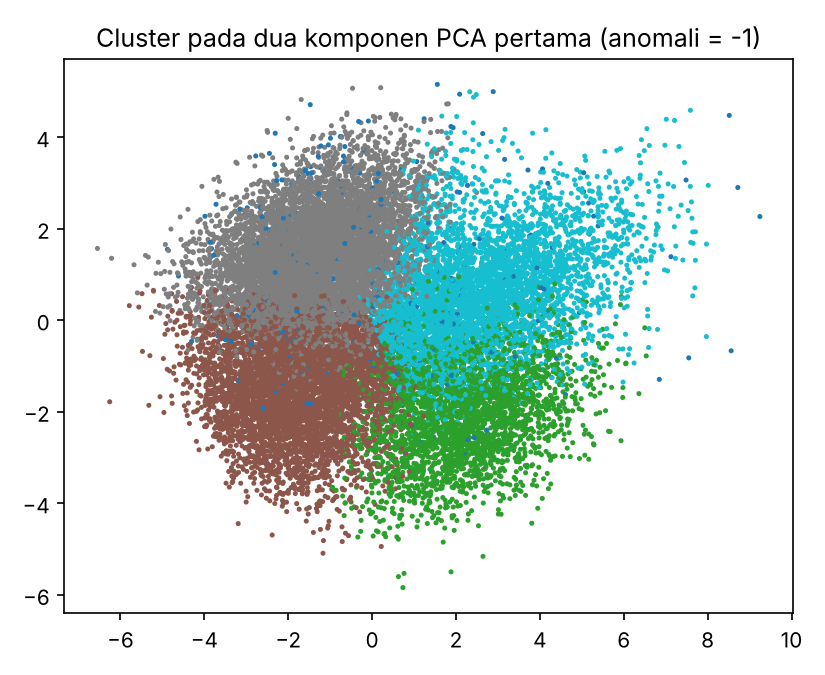

*Gambar 10. Cluster pada dua komponen PCA pertama (anomali = -1)*

Nama dan ciri disusun dari profil rata-rata dan median tiap segmen (tabel profil lengkap ada di `hasil/clustering.json`). Karena struktur data lemah, perbedaan antar-segmen terutama dibentuk oleh nilai belanja, frekuensi, recency, dan sensitivitas promo; porsi kategori memberi perbedaan lebih halus.

Ukuran akhir: -1: 1,828, 0: 16,358, 1: 27,130, 2: 41,371, 3: 26,577, 4: 6,736. Keluaran `cluster.csv` berisi 120.000 baris, satu per pelanggan.

## 4. Keterbatasan dan catatan penting

**Regresi.** Skor mentah pada test akan terpengaruh outlier ekstrem yang tidak dapat diprediksi. Kalibrasi conformal hanya per layanan, bukan per pulau atau kurir. Kurir K13 tidak punya data latih; prediksinya mengandalkan jalur 'tak dikenal'.

**Klasifikasi.** Batas kematangan label (10 Agu) dipilih dari pola laju mingguan dan bisa kurang tepat. Adaptasi terhadap pola QRIS baru didasarkan pada hanya 47 fraud dan dipilih pada jendela uji kecil (76 fraud); performa pada Sep-Okt tidak terjamin. Geseran kovariat (AUC adversarial sekitar 0,84) belum hilang sepenuhnya. Validasi keputusan biaya hanya berdasar 207 fraud, sehingga selisih antar kalibrasi tidak signifikan. Laju fraud test tidak diketahui; kalibrasi mengandaikan laju mirip periode latih matang (sekitar 0,7%).

**Clustering.** Struktur lemah (silhouette sekitar 0,08), kriteria pemilihan K tidak sepakat, dan K=4 adalah kompromi. Ambang eta kuadrat 0,02 dan ambang lembah anomali adalah pilihan analis. Penetapan nama dan aksi segmen bersifat interpretatif.

## 5. Penggunaan alat AI

Alat AI (Claude, Anthropic) digunakan untuk membantu merancang pipeline, menulis dan men-debug kode, serta menyusun laporan ini. Rincian per bagian, cara verifikasi, dan peran tiap anggota ada di `kontribusi.md`. Seluruh angka dalam laporan ini berasal dari keluaran kode yang dapat dijalankan ulang dengan satu perintah.